In [26]:
import pandas as pd
df = pd.read_csv("../data/raw/spotify-tracks-dataset.csv")
print(df.shape)
df.head()

(114000, 22)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0.1      114000 non-null  int64  
 1   Unnamed: 0        114000 non-null  int64  
 2   track_id          114000 non-null  str    
 3   artists           113999 non-null  str    
 4   album_name        113999 non-null  str    
 5   track_name        113999 non-null  str    
 6   popularity        114000 non-null  int64  
 7   duration_ms       114000 non-null  int64  
 8   explicit          114000 non-null  bool   
 9   danceability      114000 non-null  float64
 10  energy            114000 non-null  float64
 11  key               114000 non-null  int64  
 12  loudness          114000 non-null  float64
 13  mode              114000 non-null  int64  
 14  speechiness       114000 non-null  float64
 15  acousticness      114000 non-null  float64
 16  instrumentalness  114000 non-nu

In [28]:
print(df["track_id"].duplicated().sum())

24259


In [29]:
features = ["danceability", "energy", "loudness", "speechiness",
            "acousticness", "instrumentalness", "valence", "tempo"]
df[features].describe()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
count,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,0.566800,0.641383,-8.258960,0.084652,0.314910,0.156050,0.474068,122.147837
std,0.173542,0.251529,5.029337,0.105732,0.332523,0.309555,0.259261,29.978197
min,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.456000,0.472000,-10.013000,0.035900,0.016900,0.000000,0.260000,99.218750
50%,0.580000,0.685000,-7.004000,0.048900,0.169000,0.000042,0.464000,122.017000
75%,0.695000,0.854000,-5.003000,0.084500,0.598000,0.049000,0.683000,140.071000
max,0.985000,1.000000,4.532000,0.965000,0.996000,1.000000,0.995000,243.372000


In [30]:
df["track_genre"].value_counts()

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
               ... 
techno         1000
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
Name: count, Length: 114, dtype: int64

In [31]:
df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])

exclude = ["comedy", "children", "kids", "disney", "sleep", "study",
           "opera", "new-age", "show-tunes", "romance", "sad"]
print([g for g in exclude if g not in df["track_genre"].unique()])  # should print []

df = df.dropna()
df = df[~df["track_genre"].isin(exclude)]
df = df.drop_duplicates(subset="track_id")
# Same song appears under different track_ids (remixes, re-releases, albums).
# Keep the most popular version of each title + main artist.
df["main_artist"] = df["artists"].str.split(";").str[0]
df = df.sort_values("popularity", ascending=False)
df = df.drop_duplicates(subset=["track_name", "main_artist"])
df = df[(df["tempo"] > 0)
        & (df["duration_ms"].between(120_000, 420_000))
        & (df["speechiness"] < 0.66)]
df = df.reset_index(drop=True)
print(df.shape)

[]
(65416, 21)


In [32]:
from sklearn.preprocessing import StandardScaler

FEATURES = ["energy", "valence", "tempo", "danceability",
            "loudness", "acousticness", "instrumentalness"]

scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])

print(X.shape)
print(X.mean(axis=0).round(2))
print(X.std(axis=0).round(2))

(65416, 7)
[-0.  0.  0. -0. -0.  0.  0.]
[1. 1. 1. 1. 1. 1. 1.]


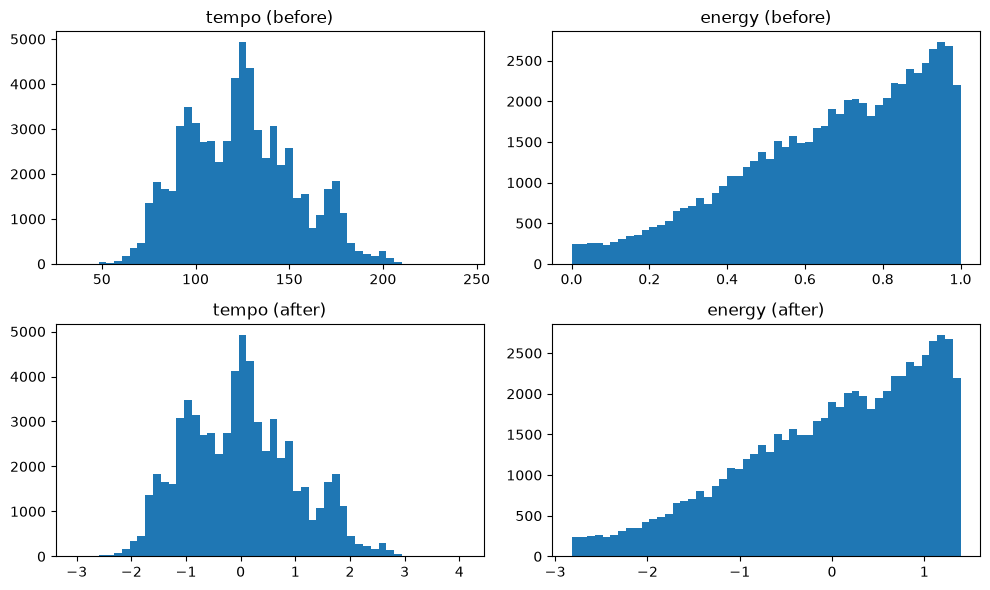

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

# Before scaling (original values)
axes[0, 0].hist(df["tempo"], bins=50)
axes[0, 0].set_title("tempo (before)")
axes[0, 1].hist(df["energy"], bins=50)
axes[0, 1].set_title("energy (before)")

# After scaling (columns 2 and 1 of X, in FEATURES order)
axes[1, 0].hist(X[:, 2], bins=50)
axes[1, 0].set_title("tempo (after)")
axes[1, 1].hist(X[:, 0], bins=50)
axes[1, 1].set_title("energy (after)")

plt.tight_layout()
plt.show()

2 345195 0.278
3 289737 0.2
4 254704 0.209
5 221759 0.224
6 203255 0.204
7 191940 0.186
8 182870 0.178
9 173745 0.175
10 165635 0.177


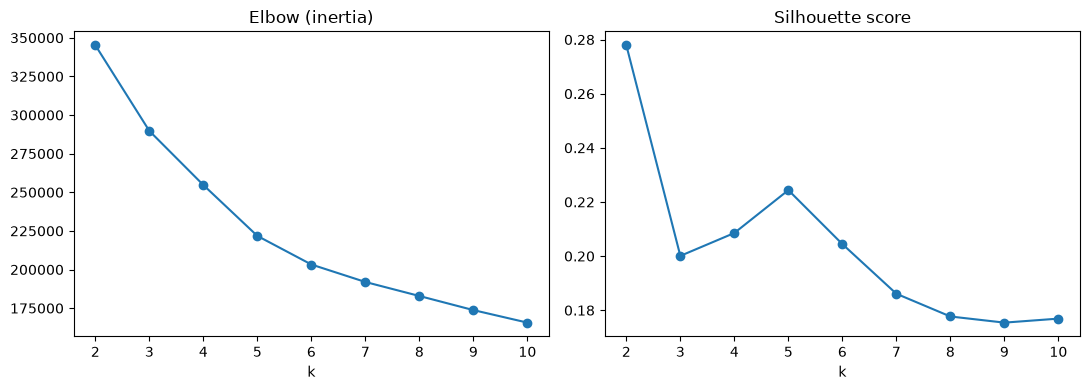

In [34]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

K_RANGE = range(2, 11)
inertias = []
silhouettes = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels, sample_size=10000, random_state=42))
    print(k, round(inertias[-1]), round(silhouettes[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(K_RANGE, inertias, marker="o")
axes[0].set_title("Elbow (inertia)")
axes[0].set_xlabel("k")
axes[1].plot(K_RANGE, silhouettes, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [35]:
from sklearn.cluster import KMeans

# Fit K-Means with k=5 (chosen from the elbow + silhouette scores)
km = KMeans(n_clusters=5, n_init=10, random_state=42)
df["cluster"] = km.fit_predict(X)

# Average feature values per cluster, in original units
profile = df.groupby("cluster")[FEATURES].mean().round(2)
profile["size"] = df["cluster"].value_counts().sort_index()
display(profile)

# 6 random songs per cluster, to sanity-check by ear
for c in range(5):
    print(f"--- cluster {c} ---")
    print(df[df["cluster"] == c][["track_name", "artists", "track_genre"]]
          .sample(6, random_state=1).to_string(index=False))

,energy,valence,tempo,danceability,loudness,acousticness,instrumentalness,size
cluster,,,,,,,,
0,0.18,0.20,108.53,0.39,-20.44,0.86,0.82,3015
1,0.74,0.70,118.42,0.69,-6.33,0.22,0.02,22589
2,0.83,0.37,139.56,0.47,-5.25,0.07,0.03,18040
3,0.41,0.41,114.51,0.55,-10.21,0.64,0.03,14437
4,0.78,0.35,128.81,0.58,-7.92,0.08,0.78,7335


--- cluster 0 ---
                                             track_name                                                              artists    track_genre
                                        Attack on Titan                                                                 Kato          anime
Meditación Budista (Musica de Relajacion para Escuchar)                                                        Reiki Armonía    world-music
                             Interstellar Docking Scene                                                          Eiro Nareth         guitar
              To Zuccabar - From "Gladiator" Soundtrack Hans Zimmer;Djivan Gasparyan;Gavin Greenaway;The Lyndhurst Orchestra         german
                                  Sky Train - Vocal Mix                                                    Omar S;Nite Jewel detroit-techno
                                               Outlined                                                              Spuntic        iranian
--

In [40]:
CLUSTER_NAMES = {
    0: "calm-instrumentals",
    1: "upbeat",
    2: "hype-aggressive",
    3: "chill-laidback",
    4: "intense",
}

# Cluster 0 (calm instrumentals) is excluded since it is not suitable for gym music. The remaining clusters can be used for different workout phases.
PHASE_CLUSTERS = {
    "warmup": [1],
    "peak": [2, 4],
    "cooldown": [3],
}

df["cluster_name"] = df["cluster"].map(CLUSTER_NAMES)
df["cluster_name"].value_counts()

cluster_name
upbeat                22589
hype-aggressive       18040
chill-laidback        14437
intense                7335
calm-instrumentals     3015
Name: count, dtype: int64

In [44]:
import numpy as np
import pandas as pd

# Styles that rarely suit a workout. Edit this list to taste.
GYM_EXCLUDE_GENRES = ["honky-tonk", "bluegrass", "tango", "country", "folk",
                      "gospel", "jazz", "blues", "rockabilly", "classical", "opera"]

def top_matches(target, clusters, n=20, pool_size=100, min_popularity=40,
                exclude_genres=GYM_EXCLUDE_GENRES, seed=None):
    t = scaler.transform(pd.DataFrame([target])[FEATURES])

    # Candidates: right clusters, popular enough, not an excluded genre
    mask = df["cluster"].isin(clusters) & (df["popularity"] >= min_popularity)
    if exclude_genres:
        mask &= ~df["track_genre"].isin(exclude_genres)
    mask = mask.to_numpy()

    # Straight-line distance from the target to each candidate
    dist = np.linalg.norm(X[mask] - t, axis=1)
    out = df[mask].copy()
    out["distance"] = dist

    # Closest first, so the pool really is the closest songs
    out = out.sort_values("distance")
    
    # Take the closest `pool_size` songs, then randomly pick n of them,
    # so each call can give a different playlist
    pool = out.head(pool_size)
    return pool.sample(n=min(n, len(pool)), random_state=seed).sort_values("distance")

peak_target = {"energy": 0.9, "valence": 0.4, "tempo": 135,
               "danceability": 0.55, "loudness": -5,
               "acousticness": 0.1, "instrumentalness": 0.1}

warmup_target = {"energy": 0.6, "valence": 0.6, "tempo": 110,
                 "danceability": 0.65, "loudness": -8,
                 "acousticness": 0.2, "instrumentalness": 0.05}

cooldown_target = {"energy": 0.35, "valence": 0.4, "tempo": 100,
                   "danceability": 0.5, "loudness": -11,
                   "acousticness": 0.6, "instrumentalness": 0.05}

cols = ["track_name", "artists", "track_genre", "energy", "tempo", "distance"]

print("WARMUP")
display(top_matches(warmup_target, PHASE_CLUSTERS["warmup"])[cols])

print("COOLDOWN")
display(top_matches(cooldown_target, PHASE_CLUSTERS["cooldown"])[cols])
result = top_matches(peak_target, PHASE_CLUSTERS["peak"])
result[["track_name", "artists", "track_genre", "energy", "tempo", "distance"]]

WARMUP


,track_name,artists,track_genre,energy,tempo,distance
16118,Vaathil Melle,Sachin Warrier,malay,0.567,103.971,0.493587
17695,Senhor fazei de mim (Um instrumento de tua paz),Marcelo Falcão,brazil,0.571,108.030,0.534767
21029,Pai,Marcos Antônio,brazil,0.574,117.048,0.547959
18741,Você Não Sabe Amar - Ao Vivo,Chico Rey & Paraná,sertanejo,0.608,105.967,0.571779
2765,grace,Fujii Kaze,j-pop,0.685,108.971,0.584099
29888,Lluvia,Charly García,punk-rock,0.710,110.005,0.646551
13804,El Tiempo Pasará,Lori Meyers,spanish,0.698,108.022,0.646744
15743,Girls Just Wanna Have Some,Chromatics,synth-pop,0.629,115.002,0.665820
27201,Kalmalısın,Barış Kocatürk,singer-songwriter,0.645,121.999,0.669686
6885,Don't Shut Me Down,ABBA,swedish,0.604,99.993,0.675815


COOLDOWN


,track_name,artists,track_genre,energy,tempo,distance
20852,Romaria - Remasterizado,Renato Teixeira,mpb,0.346,92.412,0.361252
29120,Bicho de Sete Cabeças - Ao Vivo,Geraldo Azevedo;Elba Ramalho,mpb,0.354,104.297,0.563379
29170,Paratodos,Chico Buarque,mpb,0.395,90.624,0.591116
5760,World Spins Madly On,The Weepies;Deb Talan;Steve Tannen,acoustic,0.311,107.612,0.655680
23748,A Viagem,Roupa Nova,mpb,0.401,84.800,0.676921
23394,Corre Pro Meu Mar,Maneva;Gabriel Elias,brazil,0.399,91.997,0.740794
8328,Without a Light,Drew Holcomb & The Neighbors,acoustic,0.435,87.952,0.750165
2758,Numbers,TEMPOREX,garage,0.332,93.958,0.786867
7290,Tumhi Dekho Naa,Shankar-Ehsaan-Loy;Sonu Nigam;Alka Yagnik,pop-film,0.448,81.131,0.836320
12489,Always On My Mind - Rehearsal,Elvis Presley,rock-n-roll,0.463,92.279,0.846104


,track_name,artists,track_genre,energy,tempo,distance
9451,Koolaid,Accept,heavy-metal,0.904,129.016,0.446780
888,Memories (feat. Kid Cudi),David Guetta;Kid Cudi,edm,0.916,129.983,0.561208
3029,Not In The Mood (feat. Fivio Foreign & Kay Flock),Lil Tjay;Fivio Foreign;Kay Flock,r-n-b,0.820,141.908,0.570328
13283,LN Granada,Supersubmarina,spanish,0.919,140.009,0.584917
2735,A Place for My Head,Linkin Park,alternative,0.908,133.063,0.593636
4573,Water,Bicep;Clara La San,ambient,0.822,130.013,0.603300
15704,This Is Our Time - Live,Planetshakers,world-music,0.947,128.027,0.603359
13806,Overfly,Luna Haruna,anime,0.854,133.954,0.605241
15665,Acalma Minha Tempestade,Frei Gilson,brazil,0.907,134.014,0.606380
24436,Runaway,LeBrock,synth-pop,0.871,129.980,0.608675
